In [1]:
%load_ext autoreload
%autoreload 2

In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from helpers import *
import os

from helpers import *
from Code.costs import *
from Code.implementations import *

from Code.Logistic_SGD import stochastic_logistic_regression_reg, cross_validation_logreg

In [180]:
data_path = "data/dataset"
x_train_o, x_test_o, y_train_o, train_ids, test_ids = load_csv_data(data_path)

In [256]:
print('Percentage healthy:', 100 -len(y_train_o[y_train_o==1])/len(y_train_o[y_train_o==-1])*100)

90.31454739938495

In [ ]:
# PANDAS ONLY FOR CORRECTING RIGHT COLUMNS DURING PREPROCESSING
x_train_path = os.path.join(data_path, 'x_train.csv')
df_x_train = pd.read_csv(x_train_path)

In [ ]:
def recode(x, names):
    x = x.copy()
    idx = {n: i for i, n in enumerate(names)}

    for n in ["PHYSHLTH", "MENTHLTH", "POORHLTH"]:        
        if n in idx:
            c = x[:, idx[n]]
            c[c == 88] = 0 # 88 stands for none
            c[np.isin(c, [77, 99])] = np.nan # 77 and 99 stand for no data

    for n in ["CVDSTRK3", "SEX", "DIFFWALK", "TOLDHI2", "BPMEDS"]:
        if n in idx:
            c = x[:, idx[n]]
            c[np.isin(c, [7, 9])] = np.nan 
            x[:, idx[n]] = np.where(np.isnan(c), np.nan, (c == 1).astype(float))
    return x

x_train = recode(x_train_o, df_x_train.columns)
x_test = recode(x_test_o,  df_x_train.columns)

# Basic Feature selection and Preprocessing

In [ ]:
# more than 80% NaN values
nan_ratio = np.isnan(x_train).mean(axis=0)
mask = nan_ratio < 0.8
x_tr = x_train[:, mask]
x_te = x_test[:, mask]   

# replacing NaN by median value
med = np.nanmedian(x_tr, axis=0)
x_tr = np.where(np.isnan(x_tr), med, x_tr)
x_te = np.where(np.isnan(x_te), med, x_te)

# Normalizing features
mean = x_tr.mean(axis=0)
std = x_tr.std(axis=0)
std[std == 0] = 1.0
x_tr = (x_tr - mean) / std
x_te = (x_te - mean) / std

# Clip to remove outliers
x_tr = np.clip(x_tr, -5, 5)
x_te = np.clip(x_te, -5, 5)

# Select features with most correlation to output label
y_tr = (y_train_o == 1).astype(float)
y_c = y_tr - y_tr.mean()
corr = (x_tr * y_c[:, None]).mean(axis=0) / (y_tr.std() + 1e-12)
score = np.abs(corr)

Top_k = 100 # change amount of features to keep
top = np.argsort(score)[::-1][:Top_k]
x_tr_sel, x_te_sel = x_tr[:, top], x_te[:, top]

# adding constant to features
tx_tr = np.c_[np.ones(x_tr.shape[0]), x_tr]
tx_te = np.c_[np.ones(x_te.shape[0]), x_te]
w_initial = np.zeros(tx_tr.shape[1])

print('nb traning sample x nb features:' ,x_tr.shape)


(328135, 205)
(328135, 205)


# Logistic Regression training with SGD
K-fold cross validation over SGD learning rate and regularization strength.\
Details of code in file Logistic_SGD_balanced.py

In [ ]:
from Code.helpers import build_k_indices
from Code.Logistic_SGD_balanced import cross_validation_logreg_balanced

def best_gamma_lambda_selection_balanced(y,x, k_fold, gammas, max_iters, batch_size, lambdas, seed=1):
    """cross validation over regularisation parameter lambda and trianing rate gamma.

    Args:
        y: array, target labels
        x: array, features 
        k_fold: integer, the number of folds
        gammas: shape = (p, ) where p is the number of values of gamma to test (learning rate)
        max_iters: scalar, nb of iterations of SGD
        batch_size: scalar, nb of sampled data for gradient computation
        lambdas: shape = (p, ) where p is the number of values of lambda to test (regularization strength)
    Returns:
        best_gamma : integer, value of the best gamma
        best_lambda : scalar, value of the best lambda
        best_loss : value of the cross entropy loss for the couple (best_gamma, best_lambda)
        best_thr : decision threshold for logistic regression
        test_loss_grid, train_loss_grid: arrays, for plotting purposes
    """

    # split data in k fold
    k_indices = build_k_indices(y, k_fold, seed)

    # initialize empty grids
    test_loss_grid = np.zeros((len(gammas), len(lambdas)))
    train_loss_grid = np.zeros((len(gammas), len(lambdas)))

    f1_grid = np.zeros((len(gammas), len(lambdas)))
    thr_grid = np.zeros((len(gammas), len(lambdas)))

    # learning rate
    for i, gamma in enumerate(gammas):
        print('################ Computing gamma: ', gamma, '###################')
        # regularization strength
        for j, lambda_ in enumerate(lambdas):
            print(f'Computing gamma: {gamma} & lambda: {lambda_}-------------')
            te_losses, tr_losses = [], []

            res = [cross_validation_logreg_balanced(y, x, k_indices, k, gamma, max_iters, batch_size, lambda_) for k in range(k_fold)]

            tr_losses, te_losses, f1s, thrs = map(np.array, zip(*res))
            test_loss_grid[i, j] = te_losses.mean()
            train_loss_grid[i, j] = tr_losses.mean()
            f1_grid[i, j] = f1s.mean()
            thr_grid[i, j] = thrs.mean()

            print('Test loss:',test_loss_grid[i, j], 'F1 score:',f1_grid[i, j])

    best_i, best_j = np.unravel_index(np.nanargmax(f1_grid), f1_grid.shape)

    # finding best parameters
    best_gamma = gammas[best_i]
    best_lambda = lambdas[best_j]
    best_thr = thr_grid[best_i, best_j]

    # loss of best 
    best_loss = test_loss_grid[best_i, best_j]

    return float(best_gamma), float(best_lambda), float(best_loss), float(best_thr), test_loss_grid, train_loss_grid #returning grid for plotting 

In [ ]:
import seaborn as sns

k_fold = 10 
gammas = np.logspace(-3, 0, 15) # searching grid
lambdas = [0, 0.00005, 0.0001]#np.logspace(-4, 0, 10) # searching grid
max_iters = 1500
batch_size = 512

# will take some time to run :)
best_gamma, best_lambda, best_loss, best_th, test_loss_grid, train_loss_grid = best_gamma_lambda_selection_balanced(
    y_tr, x_tr_sel, k_fold=k_fold,batch_size=batch_size, max_iters=max_iters, gammas=gammas, lambdas=lambdas)

gamma_labels = [f"{g:.1e}" for g in gammas]
lambda_labels = [f"{l:.1e}" for l in lambdas]
print(best_th)

################ Computing gamma:  0.001 ###################
Computing gamma: 0.001 & lambda: 0-------------
Test loss: 0.6995457142752969 F1 score: 0.37858521721024824
Computing gamma: 0.001 & lambda: 5e-05-------------
Test loss: 0.6995434669401813 F1 score: 0.3785899625272423
Computing gamma: 0.001 & lambda: 0.0001-------------
Test loss: 0.6995412198034924 F1 score: 0.3785792346239415
################ Computing gamma:  0.0016378937069540646 ###################
Computing gamma: 0.0016378937069540646 & lambda: 0-------------
Test loss: 0.7084480333191406 F1 score: 0.3818273298459115
Computing gamma: 0.0016378937069540646 & lambda: 5e-05-------------
Test loss: 0.7084442748366857 F1 score: 0.3818503134444698
Computing gamma: 0.0016378937069540646 & lambda: 0.0001-------------
Test loss: 0.7084405168402863 F1 score: 0.38184494332808205
################ Computing gamma:  0.0026826957952797246 ###################
Computing gamma: 0.0026826957952797246 & lambda: 0-------------
Test loss: 

In [ ]:
print('Best gamma: ',best_gamma) 
print('Best lambda: ',best_lambda)
print('Best threshold: ',best_th)

0.08483428982440717 0.0


## Create submission file 

In [245]:
x_test_path = os.path.join(data_path, 'x_test.csv')
df_x_test = pd.read_csv(x_test_path)

pred = (sigmoid(x_te_sel @ w) >= best_th).astype(int)
pred[pred == 0] = -1
create_csv_submission(df_x_test["Id"], pred, "submission_log_reg.csv")

## Create plot

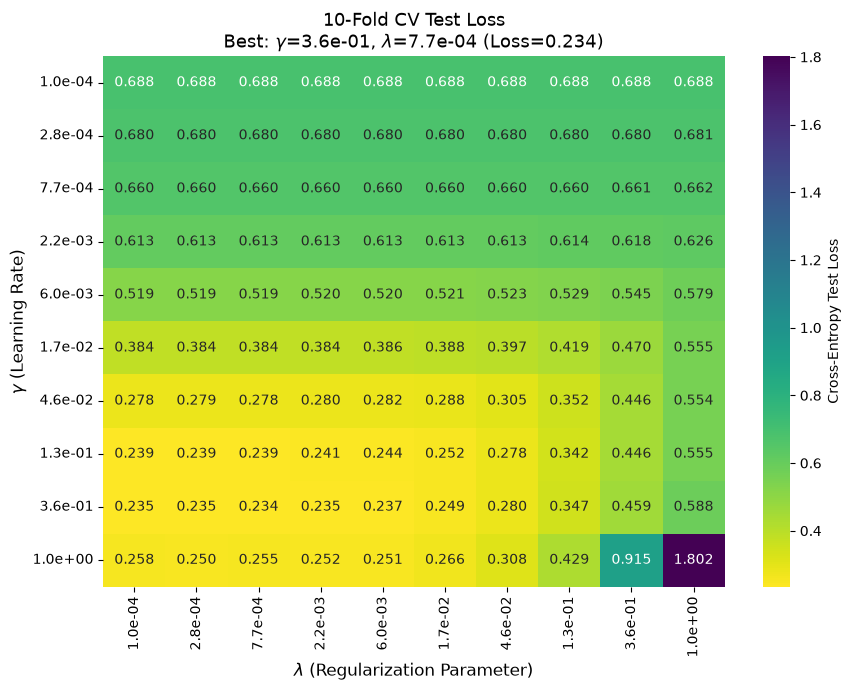

In [10]:
plt.figure(figsize=(9, 7))
sns.heatmap(
    test_loss_grid,
    xticklabels=lambda_labels,
    yticklabels=gamma_labels,
    annot=True,          # Displays loss values in cells
    fmt=".3f",          # 3 decimal places
    cmap="viridis_r",    # Darker/richer color represents lower loss
    cbar_kws={'label': 'Cross-Entropy Test Loss'}
)

plt.xlabel(r"$\lambda$ (Regularization Parameter)", fontsize=12)
plt.ylabel(r"$\gamma$ (Learning Rate)", fontsize=12)
plt.title(f"10-Fold CV Test Loss\nBest: $\\gamma$={best_gamma:.1e}, $\\lambda$={best_lambda:.1e} (Loss={best_rmse:.3f})", fontsize=13)
plt.tight_layout()
plt.show()